# Семинар 2

**Данные:** PBMC 3k (периферическая кровь человека, 10x Genomics)

В первом семинаре мы получили матрицу экспрессии, провели QC, нормализацию, выбрали 2000 высоковариабельных генов (HVG) и построили PCA. Теперь мы хотим ответить на два разных вопроса:

1. **Какие клетки образуют группы?** Для этого строим граф ближайших соседей и применяем Leiden.
2. **Как показать тысячи клеток на одном двумерном графике?** Для этого используем UMAP или t-SNE.

> **Главное различие:** Leiden определяет кластеры **на графе соседства**, построенном по координатам PCA. UMAP и t-SNE нужны прежде всего для **визуализации**, а не для установления кластеров.

## 0. Подготовка окружения

Можно продолжить работу в окружении `sc_pbmc` из первого семинара. Для Leiden нужны **`leidenalg` и `python-igraph`**

```bash
mamba create -n sc_pbmc -c conda-forge \
    python=3.11 "scanpy>=1.11,<2" scikit-misc leidenalg python-igraph \
    umap-learn scikit-learn pandas numpy scipy matplotlib \
    jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Если окружение уже создано, достаточно:

```bash
mamba activate sc_pbmc
mamba install -c conda-forge leidenalg python-igraph umap-learn scikit-learn -y
```


In [1]:
pip install scanpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 4.0 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take int

In [2]:
pip install leidenalg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 61.0 MB/s eta 0:00:00


In [3]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data
!pip install scikit-misc

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  17.9M      0 --:--:-- --:--:-- --:--:-- 17.9M
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 3.3 MB/s eta 0:00:00


In [4]:
from pathlib import Path
import scanpy as sc
import leidenalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 0.1. Продолжаем первый семинар на тех же данных PBMC 3k

- Если `data/pbmc3k_after_pca.h5ad` уже существует, загрузим готовую обработанную матрицу.
- Иначе прочитаем исходную матрицу из `data/filtered_gene_bc_matrices/hg19/` (папка из предыдущего занятия). Если её нет, Scanpy скачает PBMC 3k из своей коллекции данных и мы повторим **те же** пороги QC, HVG и PCA.

Исходные данные: [10x Genomics PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0). Функция загрузки: [`sc.datasets.pbmc3k`](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html).

In [5]:
cache = Path("data/pbmc3k_after_pca.h5ad")
raw_folder = Path("data/filtered_gene_bc_matrices/hg19")


adata = sc.read_10x_mtx(raw_folder, var_names="gene_symbols", make_unique=True)

# adata = sc.datasets.pbmc3k()

In [6]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [7]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500) &
    (adata.obs["pct_counts_mt"] < 5)
].copy()


In [8]:
adata.layers["counts"] = adata.X.copy()

In [9]:
sc.pp.highly_variable_genes(
    adata, layer="counts", flavor="seurat_v3", n_top_genes=2000
)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

In [10]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

# 1. Повторение PCA

В первом семинаре каждой клетке сопоставили вектор экспрессии генов. PCA заменяет исходные признаки координатами в новом базисе:

$$
\mathbf{x}_i=(PC_{i1},PC_{i2},\dots,PC_{ip})\in\mathbb{R}^{p}.
$$

В `adata.obsm["X_pca"]` каждая **строка соответствует клетке**, каждый **столбец — компоненте PCA**.

Евклидово расстояние между клетками $i$ и $j$ в пространстве первых $p$ компонент:

$$
d(i,j)=\left\|\mathbf{x}_i-\mathbf{x}_j\right\|_2
=\sqrt{\sum_{r=1}^{p}\left(PC_{ir}-PC_{jr}\right)^2}.
$$


In [11]:
X_pca = adata.obsm["X_pca"]
print("Первые 5 клеток, первые 5 координат PCA:")
display(pd.DataFrame(X_pca[:5, :5], index=adata.obs_names[:5],
                     columns=[f"PC{i}" for i in range(1, 6)]))

Первые 5 клеток, первые 5 координат PCA:


,PC1,PC2,PC3,PC4,PC5
AAACATACAACCAC-1,-4.729656,-0.732485,-1.319631,0.310005,-0.847269
AAACATTGAGCTAC-1,-0.771727,7.029477,4.317773,-1.829984,-1.793581
AAACATTGATCAGC-1,-3.747784,-2.741884,-2.263518,-3.970395,-1.300419
AAACCGTGCTTCCG-1,13.714365,0.483030,1.592937,-0.528195,1.163329
AAACCGTGTATGCG-1,-3.042009,-4.998953,7.369839,5.631863,1.837182


# 2. От точек к графу: kNN

**Граф** — это набор вершин и рёбер. В нашей задаче:

- вершина = одна клетка;
- ребро $i\to j$ = клетка $j$ входит в число $k$ ближайших соседей клетки $i$;
- вес ребра = численная оценка близости клеток.

Сначала алгоритм ищет **kNN — k nearest neighbors**. Это отношение в общем случае **направленное**: клетка B может входить в 2 ближайших соседа A, но клетка A может не входить в 2 ближайших соседа B.

Для графовой кластеризации обычно используют **ненаправленный взвешенный граф**. Простейшая симметризация бинарного графа — $A_{ij}^{\mathrm{sym}}=\max(A_{ij},A_{ji})$.

В Scanpy при `method="umap"` расчёт **весов** устроен сложнее: используются локально масштабированные степени принадлежности к соседству с последующим объединением направленных связей. Это **не** просто обратное евклидово расстояние.


### kNN на реальных клетках

В Scanpy используется **двухэтапная процедура**:

1. Найти ближайших соседей по координатам первых 30 PC (`n_pcs=30`).
2. По этим соседям вычислить веса связей между клетками (`connectivities`).

**Где хранятся результаты?**

| Поле AnnData | Что означает |
|---|---|
| `adata.obsm["X_pca"]` | Координаты клеток в PCA |
| `adata.obsp["distances"]` | Разреженная матрица найденных расстояний |
| `adata.obsp["connectivities"]` | Разреженная, симметричная матрица весов связей |
| `adata.uns["neighbors"]` | Параметры построения графа и ссылки на матрицы |

**Важно:** `n_neighbors=15` — локальный параметр поиска соседей. После симметризации у вершины может оказаться **больше 15 ненулевых связей**.

In [12]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    metric="euclidean",
    method="umap",
    random_state=42,
)

In [13]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'

In [14]:
G = adata.obsp["connectivities"].tocsr()
D = adata.obsp["distances"].tocsr()

In [15]:
print("Граф connectivities:", G.shape, "ненулевых элементов:", G.nnz)

print("Матрица distances:", D.shape, "ненулевых элементов:", D.nnz)

Граф connectivities: (2638, 2638) ненулевых элементов: 58162
Матрица distances: (2638, 2638) ненулевых элементов: 36932


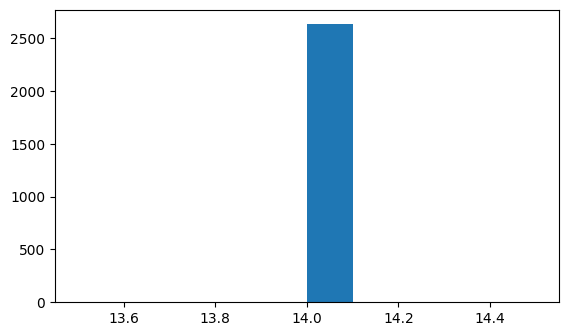

Минимум / медиана / максимум степеней: 14 14.0 14


In [16]:
degree = np.asarray((D > 0).sum(axis=1)).ravel()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(degree, bins=10)
plt.show()

print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

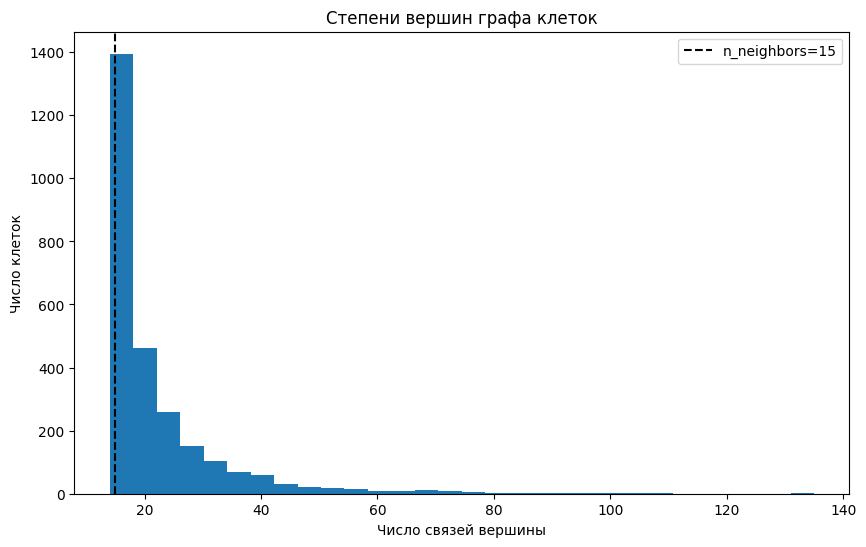

Число компонент связности: 1
Минимум / медиана / максимум степеней: 14 18.0 135


In [18]:
from scipy.sparse.csgraph import connected_components
degree = np.asarray((G > 0).sum(axis=1)).ravel()
components, labels_components = connected_components(G, directed=False)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(degree, bins=30)
ax.axvline(15, ls="--", color="black", label="n_neighbors=15")
ax.set(xlabel="Число связей вершины", ylabel="Число клеток",
       title="Степени вершин графа клеток")
ax.legend()
plt.show()
print("Число компонент связности:", components)
print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

# 3. Графовая кластеризация: Louvain → Leiden

**Кластеризация** — разбиение объектов на группы. Но «хорошая группа» должна иметь математическое определение.

- В методах типа k-means группа — набор точек, близких к общему центроиду.
- В графовых методах **сообщество** — группа вершин, которые связаны друг с другом сильнее, чем ожидалось бы при случайном соединении вершин по подходящей нулевой модели.

## 3.1. Модулярность: что оптимизирует алгоритм

Рассмотрим **ненаправленный граф** с матрицей весов $A=(A_{ij})$. Обозначим:

- $A_{ij}$ — вес ребра между вершинами $i$ и $j$;
- $k_i=\sum_j A_{ij}$ — взвешенная степень вершины $i$;
- $2m=\sum_i k_i$ — сумма весов рёбер, посчитанных по двум концам;
- $c_i$ — номер сообщества вершины $i$;
- $\mathbf{1}(c_i=c_j)$ равен единице, когда вершины в одной группе.

Одна из функций качества разбиения — **модулярность с параметром разрешения $\gamma$**:

$$
Q_{\gamma}=\frac{1}{2m}\sum_{i,j}
\left(A_{ij}-\gamma\frac{k_i k_j}{2m}\right)
\mathbf{1}(c_i=c_j).
$$

**Как понимать формулу:**

- $A_{ij}$ — наблюдаемый вес связи;
- $k_i k_j/(2m)$ — ожидаемый вес связи в модели случайного графа, сохраняющей ожидаемые степени вершин;
- в сумму попадают только пары вершин **из одной группы**;
- алгоритм пытается найти разбиение с **высоким значением $Q_\gamma$**.

$\gamma$ отвечает за масштаб: при большем $\gamma$ крупные сообщества сильнее «штрафуются», поэтому на практике часто появляются более мелкие кластеры. **Но число кластеров не обязано расти строго монотонно** из-за устройства графа и эвристической оптимизации.

## 3.2. Louvain и Leiden: чем они отличаются

**Louvain (2008):**

1. Стартует с отдельных сообществ (каждая вершина сама по себе).
2. По очереди переносит вершины между соседними сообществами, если растёт функция качества.
3. Объединяет сообщества в новые супервершины и повторяет оптимизацию.

**Проблема:** в отдельных случаях найденное сообщество может иметь плохую внутреннюю связность или даже быть несвязным.

**Leiden (2019)** добавляет **этап уточнения (refinement)** сообщества до агрегации. В результате алгоритм устраняет известную проблему несвязных сообществ Louvain и при сходимости предоставляет более сильные гарантии внутренней связности. Это **не означает**, что любой кластер Leiden биологически однороден.


Статья: [Traag, Waltman & van Eck, 2019 — From Louvain to Leiden](https://doi.org/10.1038/s41598-019-41695-z).

## 3.3. Leiden на PBMC 3k

Запустим Leiden несколько раз на **одном и том же графе**. Вызовы не используют координаты UMAP.

/tmp/ipykernel_1432/1703150331.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
/tmp/ipykernel_1432/1703150331.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1.0, key_added="leide

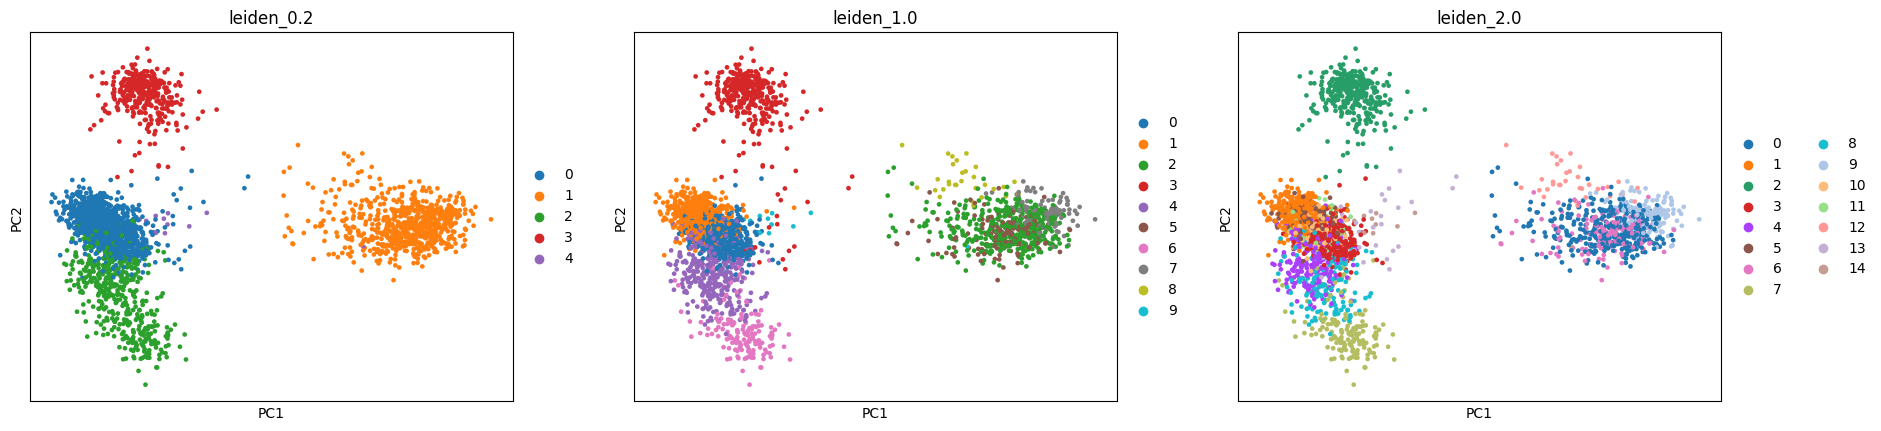

leiden_1.0
0    548
1    541
2    378
3    360
4    349
5    157
6    156
7    107
8     30
9     12
Name: count, dtype: int64


<Axes: xlabel='leiden_1.0'>

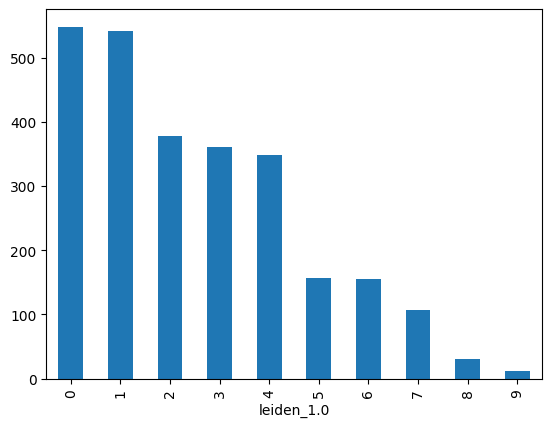

In [19]:
sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0")
sc.tl.leiden(adata, resolution=2.0, key_added="leiden_2.0")

sc.pl.pca(
    adata,
    color=["leiden_0.2", "leiden_1.0", "leiden_2.0"],
    ncols=3
)
# Посмотрим, сколько получилось кластеров
print(adata.obs["leiden_1.0"].value_counts())
adata.obs["leiden_1.0"].value_counts().sort_index().plot.bar()

# 4. Переход из 30 измерений в два: t-SNE и UMAP

## 4.1. t-SNE: сохраняем вероятности соседства

Идея t-SNE: описать, насколько клетка $j$ является соседом клетки $i$, **вероятностью**, а затем подобрать на плоскости такую картинку, чтобы отношения соседства были похожими.

В высокоразмерном пространстве PCA условные вероятности определяются расстояниями:

$$
p_{j\mid i}=\frac{\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_j\|^2}{2\sigma_i^2}\right)}
{\sum_{k\ne i}\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_k\|^2}{2\sigma_i^2}\right)},\quad p_{i\mid i}=0.
$$

Далее строятся симметричные $p_{ij}=(p_{j\mid i}+p_{i\mid j})/(2n)$.

На двумерной карте используются тяжёлые хвосты распределения Стьюдента:

$$
q_{ij}=\frac{(1+\|\mathbf y_i-\mathbf y_j\|^2)^{-1}}
{\sum_{k\ne \ell}(1+\|\mathbf y_k-\mathbf y_\ell\|^2)^{-1}}.
$$

Подбираем координаты $\mathbf y_i$, минимизируя **KL-дивергенцию**:

$$
D_{\mathrm{KL}}(P\|Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$

**Смысл:** большие $p_{ij}$ «требуют», чтобы на карте $q_{ij}$ тоже были большими. Тяжёлые хвосты помогают разнести точки, которые не являются соседями.

`perplexity` управляет эффективным масштабом локального соседства: $\operatorname{Perp}(P_i)=2^{H(P_i)}$, где энтропия считается с логарифмом по основанию 2. Это **не точное число соседей** и не число кластеров.

## 4.2. UMAP: сохраняем взвешенное локальное соседство

UMAP начинает с соседей, строит **взвешенный граф** локального соседства и ищет координаты $\mathbf y_i$ на плоскости, при которых локальные связи остаются похожими.

В упрощённой записи направленные веса близости оцениваются как

$$
w_{j\mid i}=\exp\left[-\frac{\max\{0,d(i,j)-\rho_i\}}{\sigma_i}\right],
$$

где $\rho_i$ — локальное расстояние до ближайшего ненулевого соседа, $\sigma_i$ — локальный масштаб. Вес может затем объединяться с обратным $w_{i\mid j}$ по правилу

$$
w_{ij}=w_{j\mid i}+w_{i\mid j}-w_{j\mid i}w_{i\mid j}.
$$

На плоскости близость приближается функцией вида

$$
\hat w_{ij}=\frac{1}{1+a\|\mathbf y_i-\mathbf y_j\|^{2b}},
$$

где $a,b$ зависят от настроек формы кривой. **Идея функции потерь** — кросс-энтропия между весами связей исходного графа и весами на плоскости:

$$
\mathcal L=-\sum_{i<j}\left[
 w_{ij}\log\hat w_{ij}+(1-w_{ij})\log(1-\hat w_{ij})\right].
$$

Реальная оптимизация использует приближения, включая отрицательное семплирование несоседних пар. Формула выше описывает **математическую цель**, а не буквальный полный перебор всех пар в каждой итерации.

Параметры:

- **`n_neighbors`** (в `sc.pp.neighbors`) определяет масштаб исходных локальных отношений.
- **`min_dist`** (в `sc.tl.umap`) регулирует, насколько плотно точки могут располагаться на карте.
- **`random_state`** задаёт воспроизводимый случайный старт/другие случайные шаги алгоритма.

## Полезно посмотреть
* https://github.com/NikolayOskolkov/HowUMAPWorks/blob/master/HowUMAPWorks.ipynb   
* https://pair-code.github.io/understanding-umap/

# 5.Leiden + UMAP + t-SNE

**Цель:** выполнить обе визуализации для **одних и тех же клеток и одних и тех же меток Leiden**. Только так можно корректно сравнивать полученные картинки.

`sc.tl.umap()` использует уже построенный граф соседства. `sc.tl.tsne()` ниже явно использует первые 30 PC.

In [20]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)

sc.tl.tsne(adata, use_rep="X_pca", n_pcs=30, perplexity=30, random_state=42)

In [21]:
print("UMAP:", adata.obsm["X_umap"].shape,
      "t-SNE:", adata.obsm["X_tsne"].shape)

UMAP: (2638, 2) t-SNE: (2638, 2)


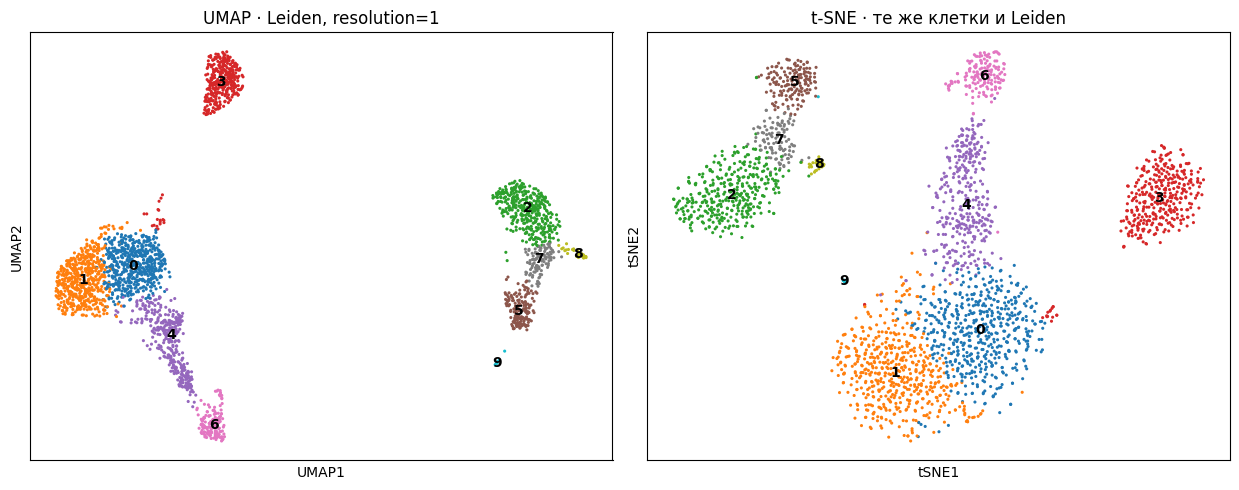

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
sc.pl.umap(adata, color="leiden_1.0", legend_loc="on data",
           title="UMAP · Leiden, resolution=1", ax=axes[0], show=False, size=20)
sc.pl.tsne(adata, color="leiden_1.0", legend_loc="on data",
           title="t-SNE · те же клетки и Leiden", ax=axes[1], show=False, size=20)
plt.tight_layout()
plt.show()

## 5.1. Проверяем, что картинка не равна кластеризации

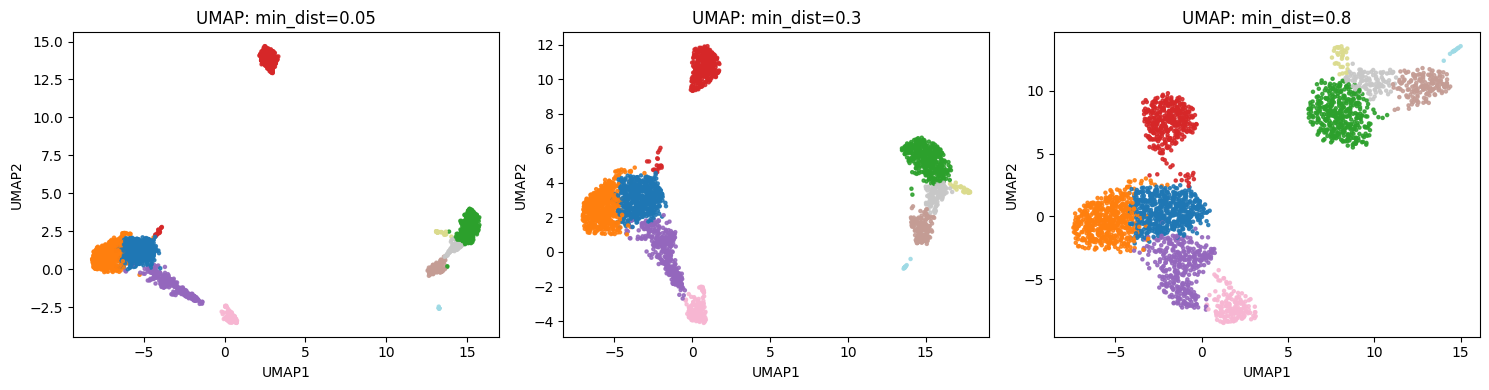

In [23]:
from copy import deepcopy
original_umap_params = deepcopy(adata.uns.get("umap", {}))
original_embedding = adata.obsm["X_umap"].copy()
original_labels = adata.obs["leiden_1.0"].copy()

embeddings = {0.3: original_embedding}
for value in (0.05, 0.8):
    sc.tl.umap(adata, min_dist=value, random_state=42)
    embeddings[value] = adata.obsm["X_umap"].copy()

adata.obsm["X_umap"] = original_embedding  # возвращаем основной UMAP
adata.uns["umap"] = original_umap_params  # и исходные параметры в AnnData
assert original_labels.equals(adata.obs["leiden_1.0"])

labels = adata.obs["leiden_1.0"].cat.codes.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (value, xy) in zip(axes, sorted(embeddings.items())):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab20", s=5, alpha=0.85)
    ax.set(title=f"UMAP: min_dist={value}", xlabel="UMAP1", ylabel="UMAP2")
plt.tight_layout()
plt.show()

## 5.2. Проверка через биологию

Окрасим UMAP по известным генам-маркерам: `CD3D` (T-клетки), `MS4A1` (B-клетки), `NKG7` (NK-клетки), `LST1` (моноциты).

In [24]:
markers = [g for g in ["CD3D", "MS4A1", "NKG7", "LST1"] if g in adata.var_names]

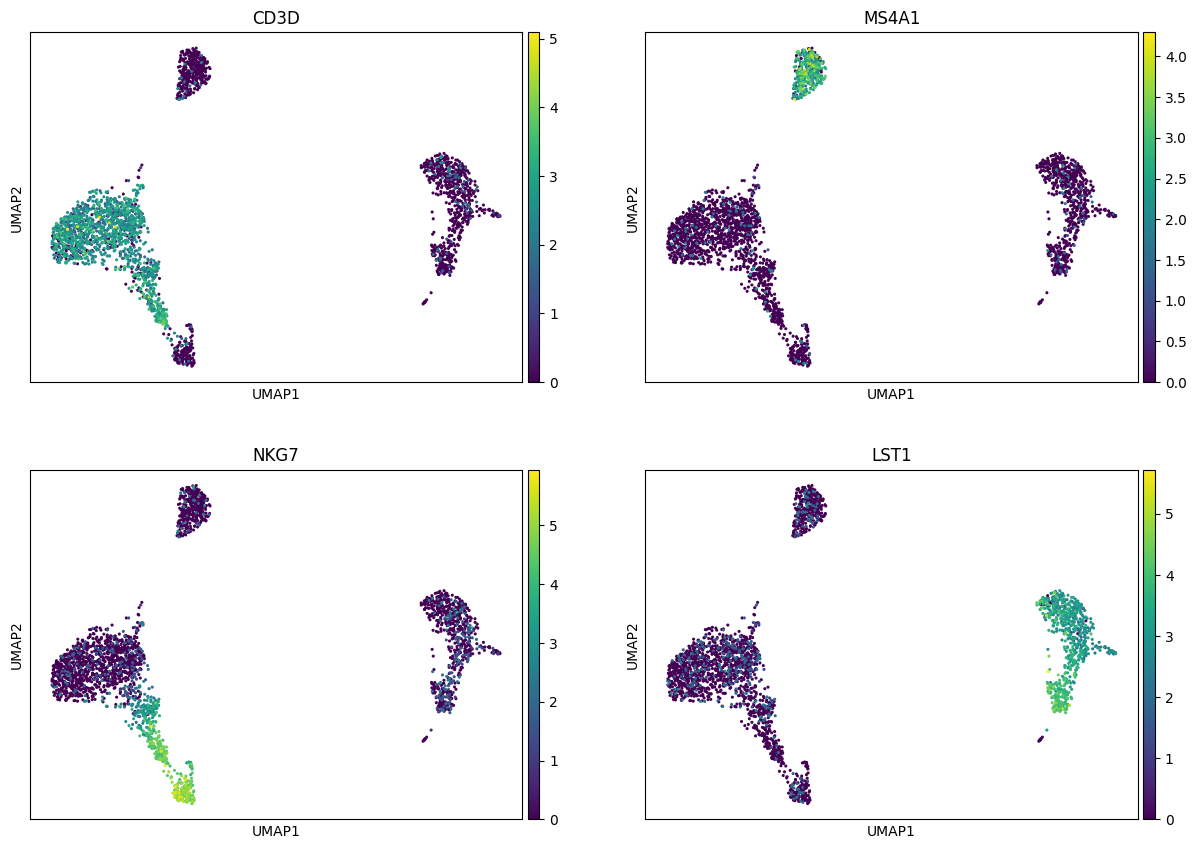

In [25]:
sc.pl.umap(adata, color=markers, ncols=2, size=20)

## 5.3. Сохраняем результаты для следующего занятия

В `.h5ad` сохраняются исходная матрица, `X_pca`, граф соседства, все варианты меток Leiden и основная визуализация `X_umap`/`X_tsne`. На следующем семинаре можно начать с аннотации кластеров, не повторяя вычисления.

In [26]:
result_path = Path("data/pbmc3k_after_clustering.h5ad")
adata.write_h5ad(result_path, compression="gzip")

# Самостоятельная работа: модулярность и анализ scRNA-seq

## Задание 1. Посчитать модулярность вручную

На рисунке показан **неориентированный невзвешенный граф из 9 вершин**. Рёбра внутри сообщества проведены сплошными линиями, между сообществами — пунктирными.

![Граф из 9 вершин](seminar6_modularity_graph.png)

Сообщества: **A = {1, 2, 3}**, **B = {4, 5, 6}**, **C = {7, 8, 9}**.

1. Посчитайте общее число рёбер графа `m`.
2. Для каждого сообщества найдите `l_c` — число рёбер, оба конца которых находятся внутри сообщества, и `d_c` — сумму степеней его вершин (включая внешние связи).
3. По формуле ниже вычислите **модулярность разбиения вручную**, показав промежуточные вычисления:

   $$Q=\sum_{c=1}^{3}\left(\frac{l_c}{m}-\left(\frac{d_c}{2m}\right)^2\right).$$

4. Объясните словами, зачем из доли внутренних рёбер вычитается второй член. Что показывает положительное значение `Q`? Является ли `Q` вероятностью?

## Задание 2. Самостоятельный анализ клеток в Scanpy

**Выберите один** набор 10x Genomics (PBMC 3k не использовать):

- [Клетки сердца эмбриона мыши E18 (~1011 клеток)](https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки головного мозга эмбриона мыши E18 (~1301 клетка)](https://www.10xgenomics.com/datasets/1-k-brain-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки селезёнки мыши (~1119 клеток)](https://www.10xgenomics.com/datasets/splenocytes-from-c-57-bl-6-mice-1-k-cells-v-2-2-standard-4-0-0)

На странице набора загрузите **Feature / cell matrix HDF5 (filtered)** (для селезёнки — матрицу **Gene Expression**, а не V(D)J). Это счётчики UMI для баркодов, уже отобранных Cell Ranger; исходные пустые капли в эту матрицу не входят.

```python
import scanpy as sc
adata = sc.read_10x_h5("путь/к/скачанному_файлу.h5")
adata.var_names_make_unique()
```

**Проведите анализ**, используя методы Scanpy, изученные на семинарах:

1. **QC.** Посчитайте и покажите распределения количества UMI (`total_counts`), обнаруженных генов (`n_genes_by_counts`) и доли митохондриальных счётчиков (`pct_counts_mt`). Выберите пороги фильтрации клеток и генов, примените их и **объясните почему выбрали именно эти значения**. Укажите, сколько клеток осталось.
2. **Нормализация и HVG.** Выполните нормализацию, `log1p` и отбор высоковариабельных генов. Укажите число HVG и объясните, зачем их отбирают и почему выбранное количество разумно.
3. **PCA.** Постройте PCA. Выберите число главных компонент для дальнейшего анализа; объясните выбор, используя график доли объяснённой дисперсии.
4. **Граф и Leiden.** Постройте граф соседей, выполните кластеризацию Leiden. Укажите `n_neighbors`, `n_pcs`, `resolution`, число получившихся кластеров и число клеток в них. Объясните выбранные параметры.
5. **UMAP и t-SNE.** Постройте обе визуализации, раскрасив точки по меткам Leiden. Также раскрасьте PCA или UMAP по одной QC-метрике и по **двум выбранным известным генам**, если они есть в данных. Опишите, что видно и какие выводы сделать нельзя.
6. **Биологический вывод.** По нескольким предложениям объясните, какие клеточные популяции **предположительно** присутствуют в выбранной ткани. Обоснуйте предположение экспрессией выбранных генов; не называйте кластеры достоверно определёнными клеточными типами.

**Разрешено:** стандартные функции Scanpy для QC, фильтрации, нормализации, HVG, PCA, графа соседей, Leiden, UMAP и t-SNE; окраска графиков по кластерам, QC-метрикам и **заданным вручную** генам.

**Не использовать:** `sc.tl.rank_genes_groups`, `sc.tl.score_genes`, методы автоматической аннотации или другие ещё не изученные методы. Подбор генов можно сделать по литературе, без автоматического поиска маркеров.

**Что сдавать:** число и расчёт модулярности; Jupyter-ноутбук с анализом одного набора данных, графиками, числом клеток до/после QC, параметрами и краткими объяснениями сделанных решений. Не требуется получить «правильное» число кластеров.


## Задание 1


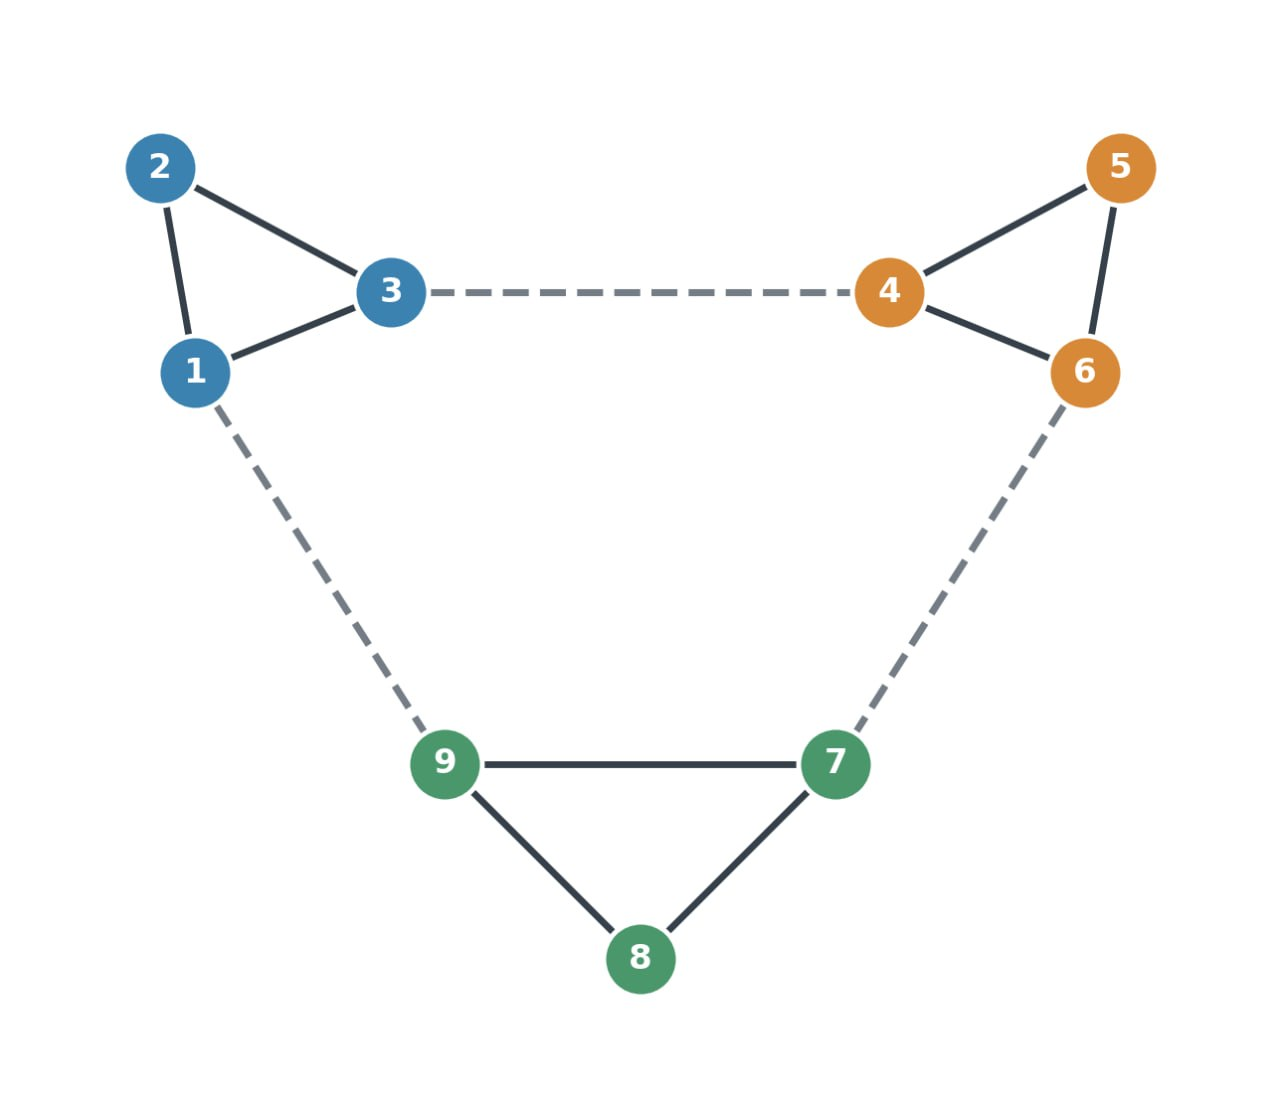

m = 12 (по 3 ребра внутри каждого треугольника + 3 пунктирных: 3–4, 1–9, 6–7).

Все три сообщества симметричны: l_c = 3, d_c = 2·3 + 2 = 8 (два внешних ребра у каждого). Проверка: 8·3 = 24 = 2m.

$$Q = 3\left(\frac{3}{12} - \left(\frac{8}{24}\right)^2\right) = 3\left(\frac14 - \frac19\right) = \frac{5}{12} \approx 0{,}417$$

Второй член - доля рёбер, которая попала бы внутрь сообщества случайно, если сохранить степени вершин и переcобрать рёбра наугад. Без него максимум давало бы тривиальное разбиение "все в одном сообществе": доля внутренних рёбер равна 1. Положительное Q означает, что внутри групп рёбер больше, чем ожидается при такой нулевой модели.

Вероятностью Q не является: это разность двух долей, она принимает значения от −0,5 до 1 и может быть отрицательной. Здесь 0,417 при теоретическом максимуме 1 − 1/3 ≈ 0,667 для трёх равных сообществ без внешних рёбер.

## Задание 2
Проба GSM5599220 — нормальная ткань яичника, полученная при операции по поводу доброкачественной муцинозной цистаденомы. Данные лежат в трёх файлах формата Cell Ranger: баркоды клеток, список генов и разреженная матрица счётчиков UMI (гены × клетки), всего около 45 МБ.


In [27]:
from pathlib import Path
import io
import tarfile
import urllib.request

import numpy as np
import pandas as pd
import scipy.io as sio
import anndata as ad
import scanpy as sc
import igraph as ig
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.set_figure_params(dpi=90, figsize=(5, 4))

DATA = Path("data/ovary")
SAMPLE = "GSM5599220"  # нормальная ткань яичника; HGSOC для сравнения — GSM5599225

In [30]:
import re

sample_dir = DATA / SAMPLE
suppl_url = f"https://ftp.ncbi.nlm.nih.gov/geo/samples/{SAMPLE[:-3]}nnn/{SAMPLE}/suppl/"

if not sample_dir.exists():
    with urllib.request.urlopen(suppl_url) as response:
        listing = response.read().decode()
    file_names = list(dict.fromkeys(re.findall(r'href="[^"]*?([^"/]+\.gz)"', listing)))
    if not file_names:
        raise RuntimeError(f"не удалось получить список файлов: {suppl_url}")

    sample_dir.mkdir(parents=True)
    for name in file_names:
        with urllib.request.urlopen(suppl_url + name) as response:
            (sample_dir / name).write_bytes(response.read())

sorted(p.name for p in sample_dir.iterdir())

['GSM5599220_Norm1.barcodes.tsv.gz',
 'GSM5599220_Norm1.genes.tsv.gz',
 'GSM5599220_Norm1.matrix.mtx.gz']

In [31]:
def find_file(folder, *patterns):
    for pattern in patterns:
        hits = sorted(folder.glob(f"*{pattern}*"))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"в {folder} нет файла с '{patterns[0]}' в имени")


def read_geo_10x(folder):
    counts = sio.mmread(find_file(folder, "matrix")).T.tocsr().astype("float32")
    genes = pd.read_csv(find_file(folder, "genes", "features"), sep="\t", header=None)
    barcodes = pd.read_csv(find_file(folder, "barcodes"), sep="\t", header=None)

    adata = ad.AnnData(counts)
    adata.obs_names = barcodes[0].values
    adata.var_names = genes[1].values if genes.shape[1] > 1 else genes[0].values
    adata.var["gene_ids"] = genes[0].values
    adata.var_names_make_unique()
    return adata


adata = read_geo_10x(sample_dir)
adata

AnnData object with n_obs × n_vars = 6370 × 27984
    var: 'gene_ids'
    layers: None (.X)

## Задание 1. Контроль качества

In [32]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

qc_cols = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
adata.obs[qc_cols].describe().round(2)

,total_counts,n_genes_by_counts,pct_counts_mt
count,6370.00,6370.00,6370.00
mean,8934.17,2352.11,11.59
std,8375.55,942.25,7.56
min,505.00,62.00,0.08
25%,5808.25,1919.00,8.48
50%,8095.50,2276.50,10.01
75%,10051.75,2661.00,12.11
max,178728.00,10592.00,96.53


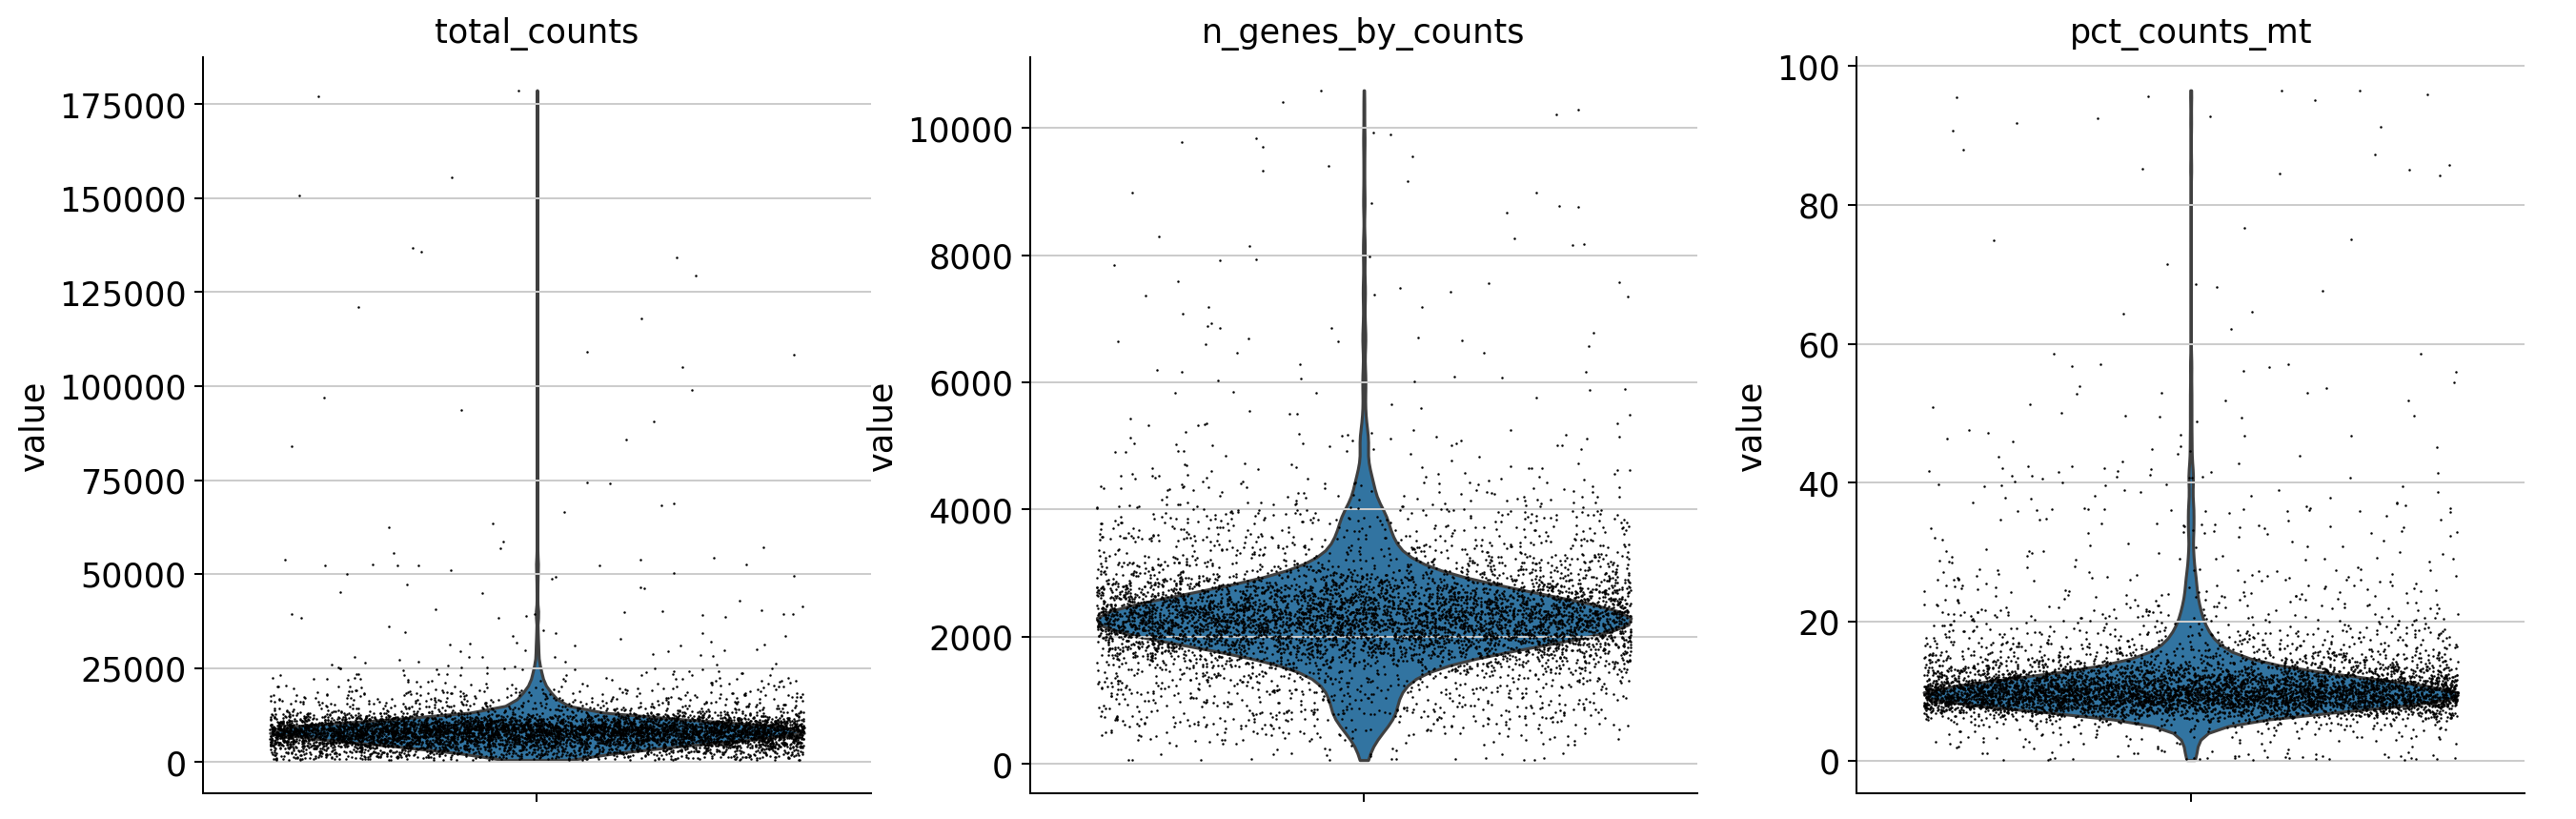

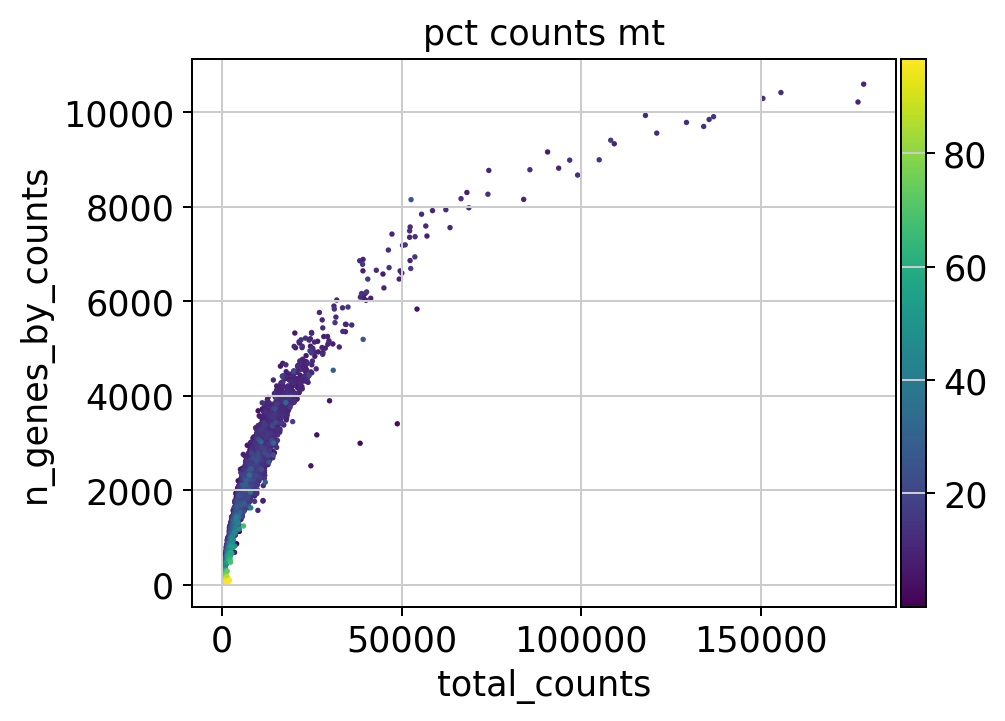

In [33]:
sc.pl.violin(adata, qc_cols, jitter=0.4, multi_panel=True)
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

In [34]:
min_genes = 300
max_genes = int(np.quantile(adata.obs["n_genes_by_counts"], 0.98))
max_mt = 15

print(f"пороги: n_genes в [{min_genes}, {max_genes}), pct_counts_mt < {max_mt}")
for name, failed in {
    "мало генов": adata.obs["n_genes_by_counts"] < min_genes,
    "много генов (возможные дублеты)": adata.obs["n_genes_by_counts"] >= max_genes,
    "высокая доля MT": adata.obs["pct_counts_mt"] >= max_mt,
}.items():
    print(f"{name}: {int(failed.sum())} клеток")

пороги: n_genes в [300, 4631), pct_counts_mt < 15
мало генов: 28 клеток
много генов (возможные дублеты): 128 клеток
высокая доля MT: 776 клеток


In [35]:
n_cells_before = adata.n_obs

sc.pp.filter_cells(adata, min_genes=min_genes)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < max_genes) &
    (adata.obs["pct_counts_mt"] < max_mt)
].copy()

print(f"клеток до фильтрации: {n_cells_before}, после: {adata.n_obs}")
print(f"генов после фильтрации: {adata.n_vars}")

клеток до фильтрации: 6370, после: 5479
генов после фильтрации: 18061


Верхняя граница по числу генов взята как 98-й процентиль (4631) — убирает 128 клеток с вероятными дублетами; нижний порог 300 отсекает всего 28 баркодов, матрица уже отфильтрована Cell Ranger. Фиксированные 2500 с семинара не подходят: 75-й процентиль равен 2661, срезали бы треть пробы.

Порог по митохондриям — 15% вместо 5% на PBMC 3k: здесь медиана 10%, нижний квартиль 8,5%, и 5% оставили бы меньше четверти клеток. Высокая доля MT — признак повреждённой мембраны, но её уровень зависит от ткани: солидную ткань дезагрегируют ферментами, а строма и мышечные клетки изначально богаче митохондриями, чем клетки крови. Уходит 776 клеток, всего 6370 в 5479.

## Задание 2. Нормализация и HVG

HVG: 2000


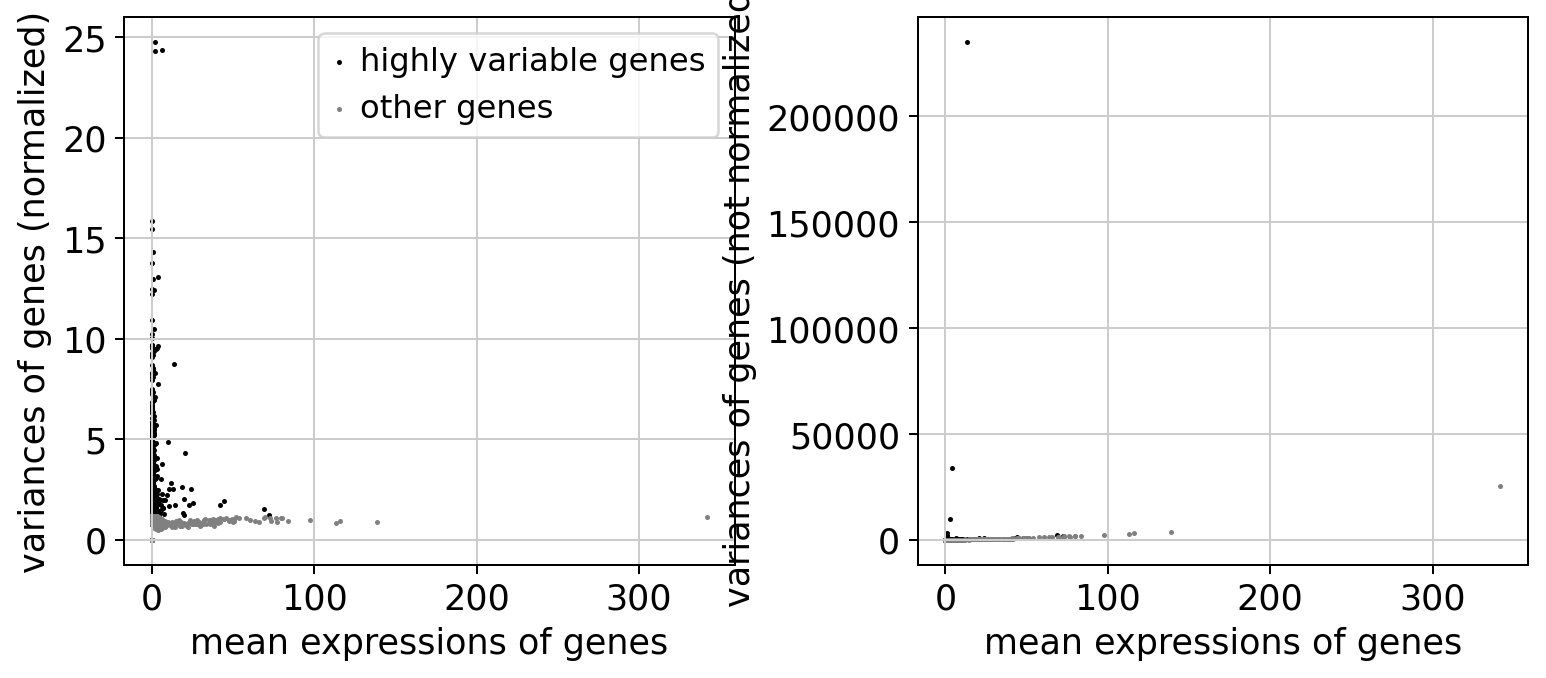

In [36]:
adata.layers["counts"] = adata.X.copy()

sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

print("HVG:", int(adata.var["highly_variable"].sum()))
sc.pl.highly_variable_genes(adata)

2000 HVG из 18 061 гена — те же настройки, что на семинаре. Большая часть генов либо почти не экспрессируется, либо одинакова во всех клетках и добавляет к расстояниям шум, а не сигнал; отбор HVG оставляет различающие клетки гены и снижает размерность перед PCA. На графике видно, зачем нужна поправка на среднее: без нормализации дисперсии (правая панель) в лидеры выходят просто самые высокоэкспрессированные гены. 200–300 — потеряем редкие популяции, взять почти все — структура утонет в технической вариации.

## Задание 3. PCA и выбор числа компонент


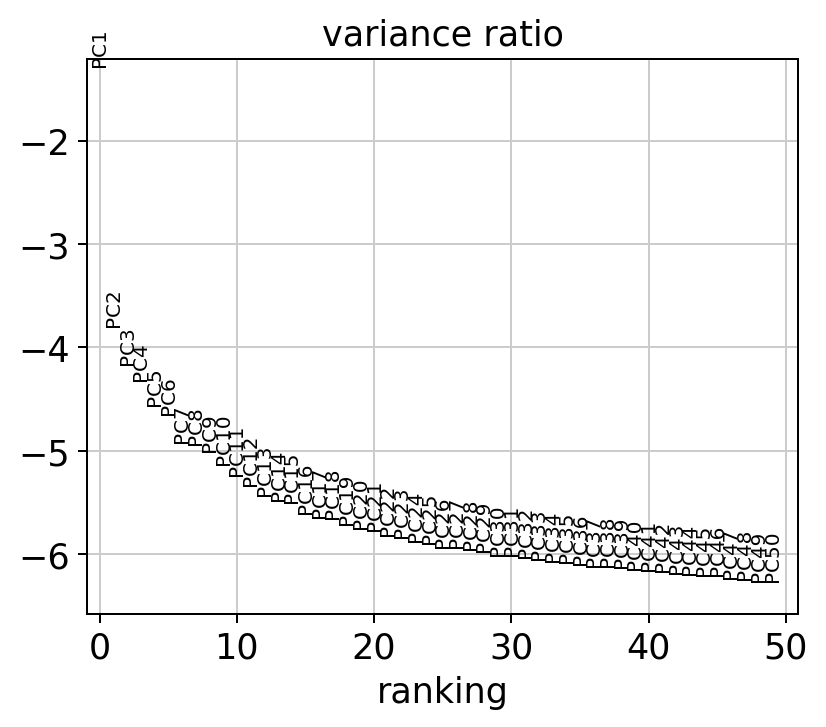

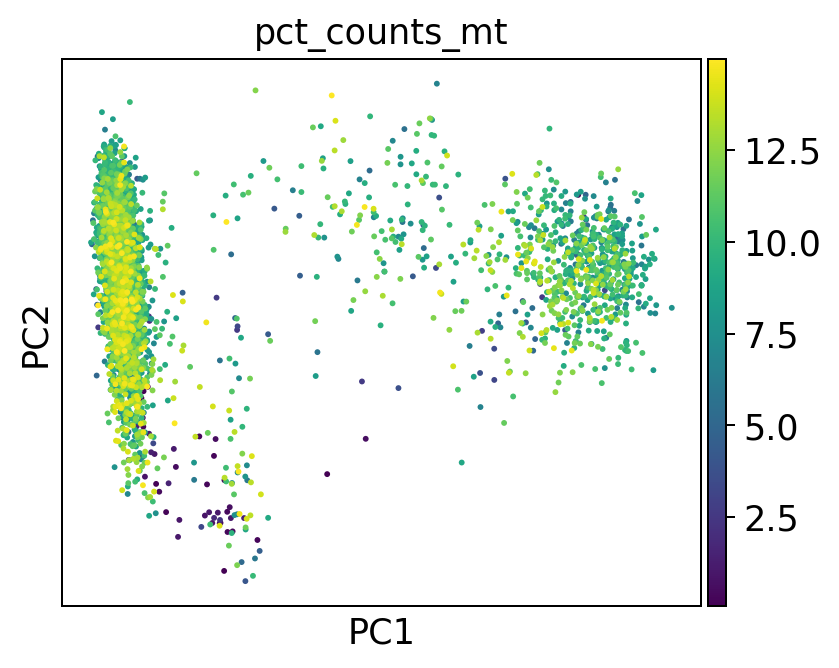

In [37]:
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pl.pca(adata, color="pct_counts_mt")

In [38]:
n_pcs = 20
variance = adata.uns["pca"]["variance_ratio"]
print(f"первые {n_pcs} PC объясняют {100 * variance[:n_pcs].sum():.1f}% дисперсии")
print("вклад PC20 / PC50:", round(float(variance[19] / variance[49]), 2))

первые 20 PC объясняют 41.8% дисперсии
вклад PC20 / PC50: 1.68


Кривая на логарифмическом графике выходит на плато после 15–20-й компоненты: дальше каждая следующая PC объясняет почти столько же, сколько предыдущая, то есть в основном шум. Берём `n_pcs = 20` — первые 20 PC дают 41,8% дисперсии, PC20 ещё в 1,68 раза информативнее PC50. Точное значение в этом диапазоне мало меняет граф соседства; важно, что это не 2 (потеряем структуру) и не 50 (добавим шумовые направления в расстояния).

На PC1/PC2 градиента по `pct_counts_mt` не видно — главные компоненты отражают различия клеточных типов, а не качество клеток.

## Задание 4. Граф соседей, Leiden и модулярность

In [39]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=n_pcs, metric="euclidean", method="umap", random_state=42)

resolutions = [0.2, 0.5, 1.0]
leiden_keys = [f"leiden_{r}" for r in resolutions]
for resolution, key in zip(resolutions, leiden_keys):
    sc.tl.leiden(adata, resolution=resolution, key_added=key, flavor="igraph",
                 n_iterations=2, directed=False, random_state=42)

pd.DataFrame({key: adata.obs[key].value_counts() for key in leiden_keys}).fillna(0).astype(int)

,leiden_0.2,leiden_0.5,leiden_1.0
0,4482,2241,474
1,227,1365,522
10,0,0,145
11,0,0,24
12,0,0,455
13,0,0,50
14,0,0,136
15,0,0,94
16,0,0,73
17,0,0,27


In [40]:
connectivities = adata.obsp["connectivities"].tocoo()
upper = connectivities.row < connectivities.col
graph = ig.Graph(n=adata.n_obs, edges=np.column_stack([connectivities.row[upper], connectivities.col[upper]]).tolist())
graph.es["weight"] = connectivities.data[upper]

for key in leiden_keys:
    membership = adata.obs[key].cat.codes.to_numpy()
    q = graph.modularity(membership, weights="weight")
    print(f"{key}: кластеров {adata.obs[key].nunique():>2}, Q = {q:.4f}")

leiden_0.2: кластеров  6, Q = 0.3040
leiden_0.5: кластеров  8, Q = 0.5951
leiden_1.0: кластеров 18, Q = 0.6650


С ростом resolution алгоритм дробит крупные сообщества: 6 - 8 - 18 кластеров. Модулярность здесь растёт вместе с ними (0,30 - 0,60 - 0,67), потому что при 0.2 один кластер забирает 4482 клетки из 5479 — такое объединение слабо связанных областей графа штрафуется. Считаем Q при γ=1, а Leiden с resolution=1 именно её и оптимизирует, так что сравнение немного подыгрывает последнему разбиению.

При этом Q — свойство графа, а не биологии: граф построен по 20 PC, нашим HVG и 15 соседям, при других параметрах максимум окажется в другом месте. Две транскрипционно разные, но связанные переходным состоянием популяции могут давать более высокое Q в объединённом виде. Число кластеров выбирают по интерпретируемости — маркерам и устойчивости при смене параметров, — а Q остаётся вспомогательной характеристикой.

## Задание 5. UMAP и t-SNE

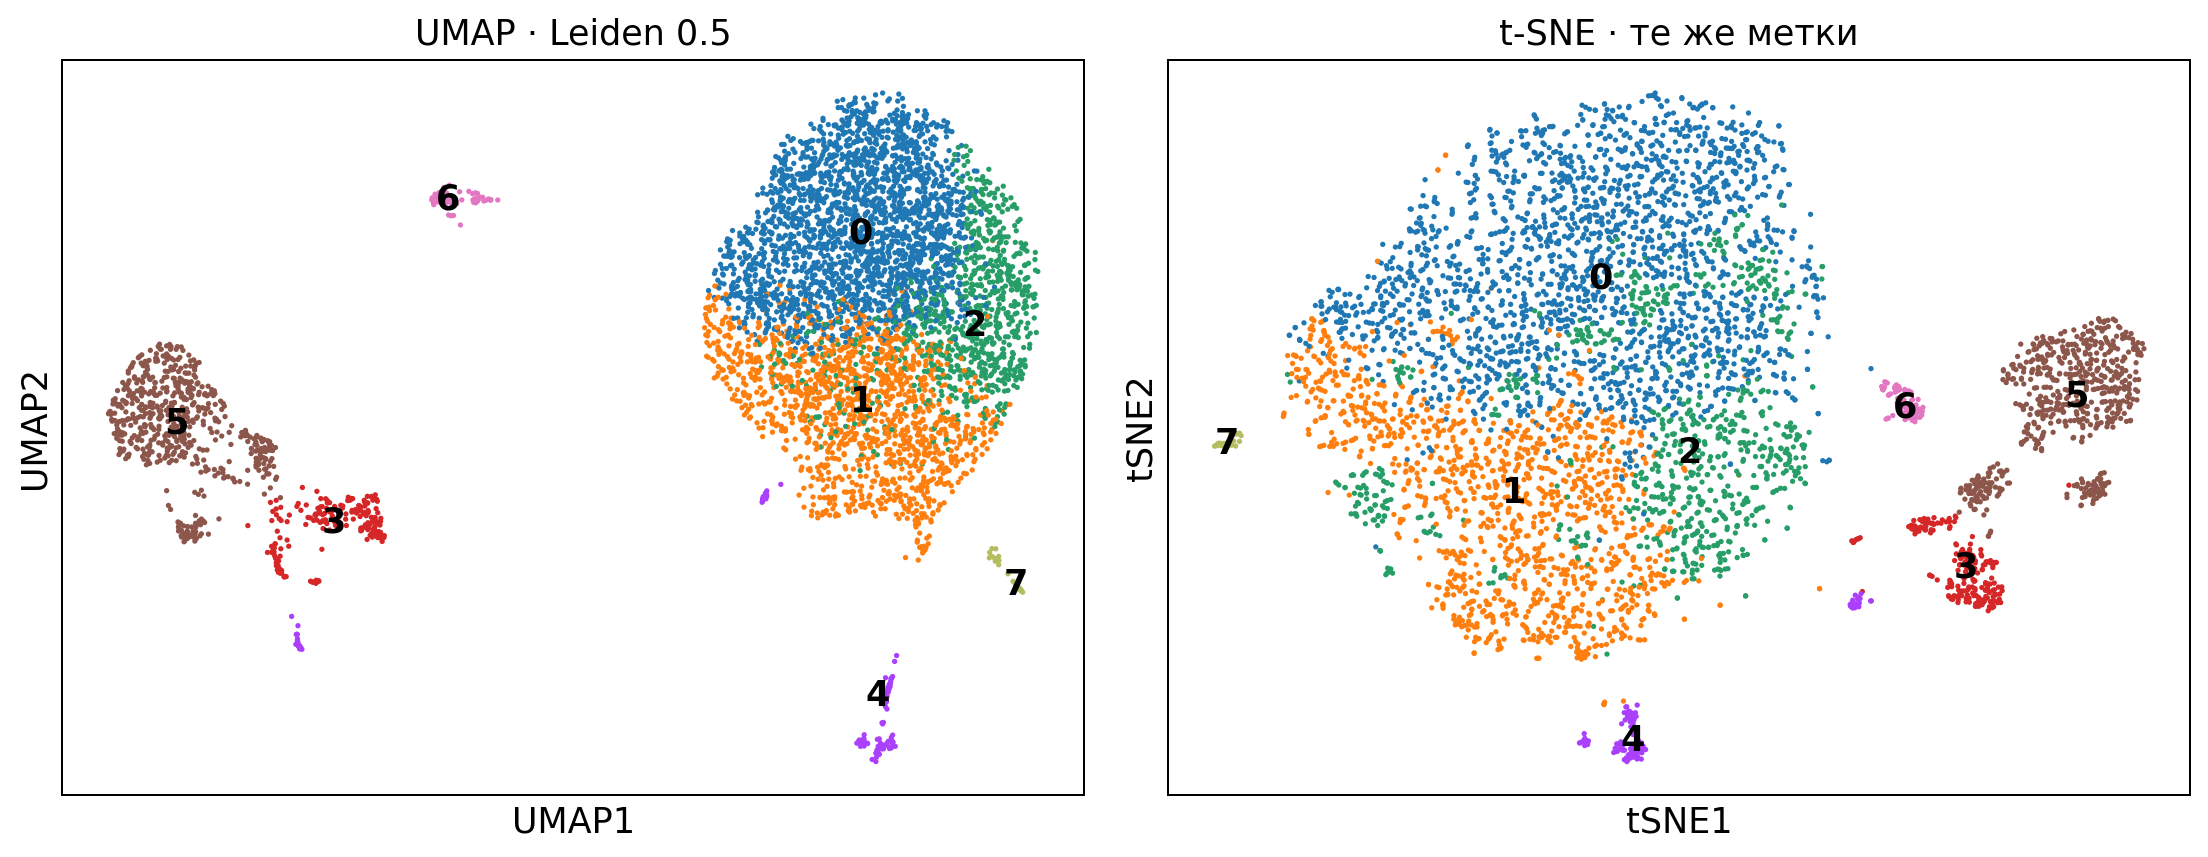

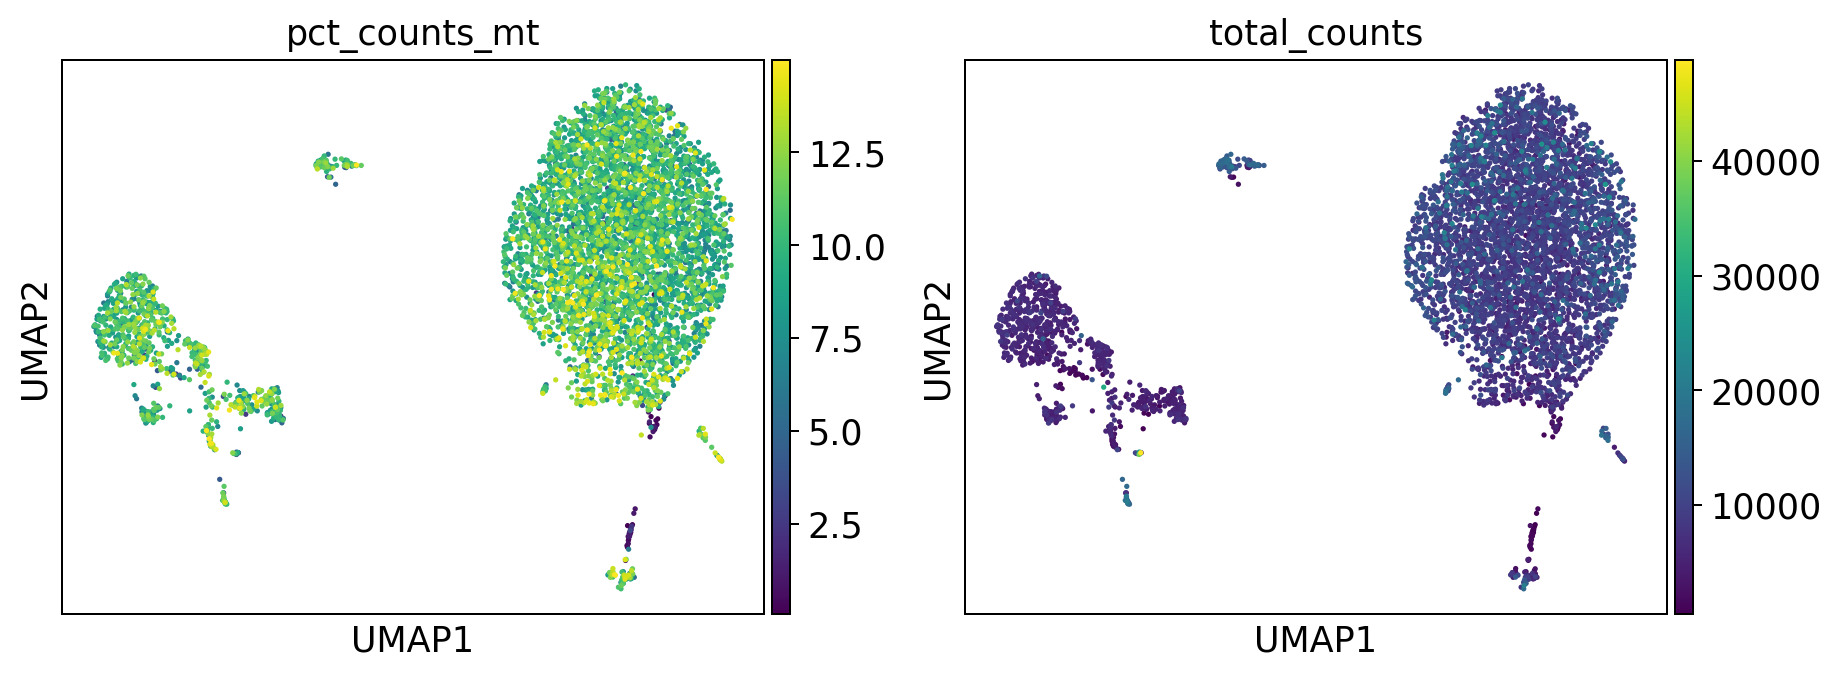

In [41]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)
sc.tl.tsne(adata, use_rep="X_pca", n_pcs=n_pcs, perplexity=30, random_state=42)

main_key = "leiden_0.5"
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
sc.pl.umap(adata, color=main_key, legend_loc="on data", title="UMAP · Leiden 0.5", ax=axes[0], show=False, size=18)
sc.pl.tsne(adata, color=main_key, legend_loc="on data", title="t-SNE · те же метки", ax=axes[1], show=False, size=18)
plt.tight_layout()
plt.show()

sc.pl.umap(adata, color=["pct_counts_mt", "total_counts"], ncols=2, size=18)

Обе картинки — проекции одного и того же графа по 20 PC: на UMAP кластеры 3 и 5 стоят слева от основного облака, на t-SNE — справа от него, а 7 переезжает с края внутрь. Метки при этом одни и те же. Доверять стоит только локальному соседству: рядом стоящие точки действительно похожи по экспрессии. Площадь «облака» не равна числу клеток, а расстояние между кластерами не пропорционально транскрипционному различию.

Число кластеров задаёт Leiden на графе, а не картинка: кластеры 0, 1 и 2 сливаются в одно сплошное облако, хотя это три сообщества. Раскраска по QC полезна как проверка артефактов — здесь `pct_counts_mt` ровная по всем кластерам, а `total_counts` различается между крупным облаком и левой группой, то есть ни один кластер не держится на одном только качестве клеток.

## Задание 6. Проверка по маркерным генам

| Популяция | Маркеры |
|---|---|
| Эпителий (в том числе поверхностный эпителий яичника) | `EPCAM`, `KRT18`, `PAX8` |
| Стромальные фибробласты | `COL1A1`, `DCN`, `LUM` |
| Гладкомышечные клетки и перициты | `ACTA2`, `RGS5`, `MYH11` |
| Эндотелий | `PECAM1`, `VWF`, `CDH5` |
| Иммунные клетки (общий маркер) | `PTPRC` |
| T-клетки | `CD3D`, `CD3E` |
| Макрофаги | `CD68`, `LYZ` |
| Гранулёзные клетки | `FOXL2`, `AMH`, `CYP19A1` |
| Тека-клетки, стероидогенные | `STAR`, `CYP17A1` |

нет в данных: []


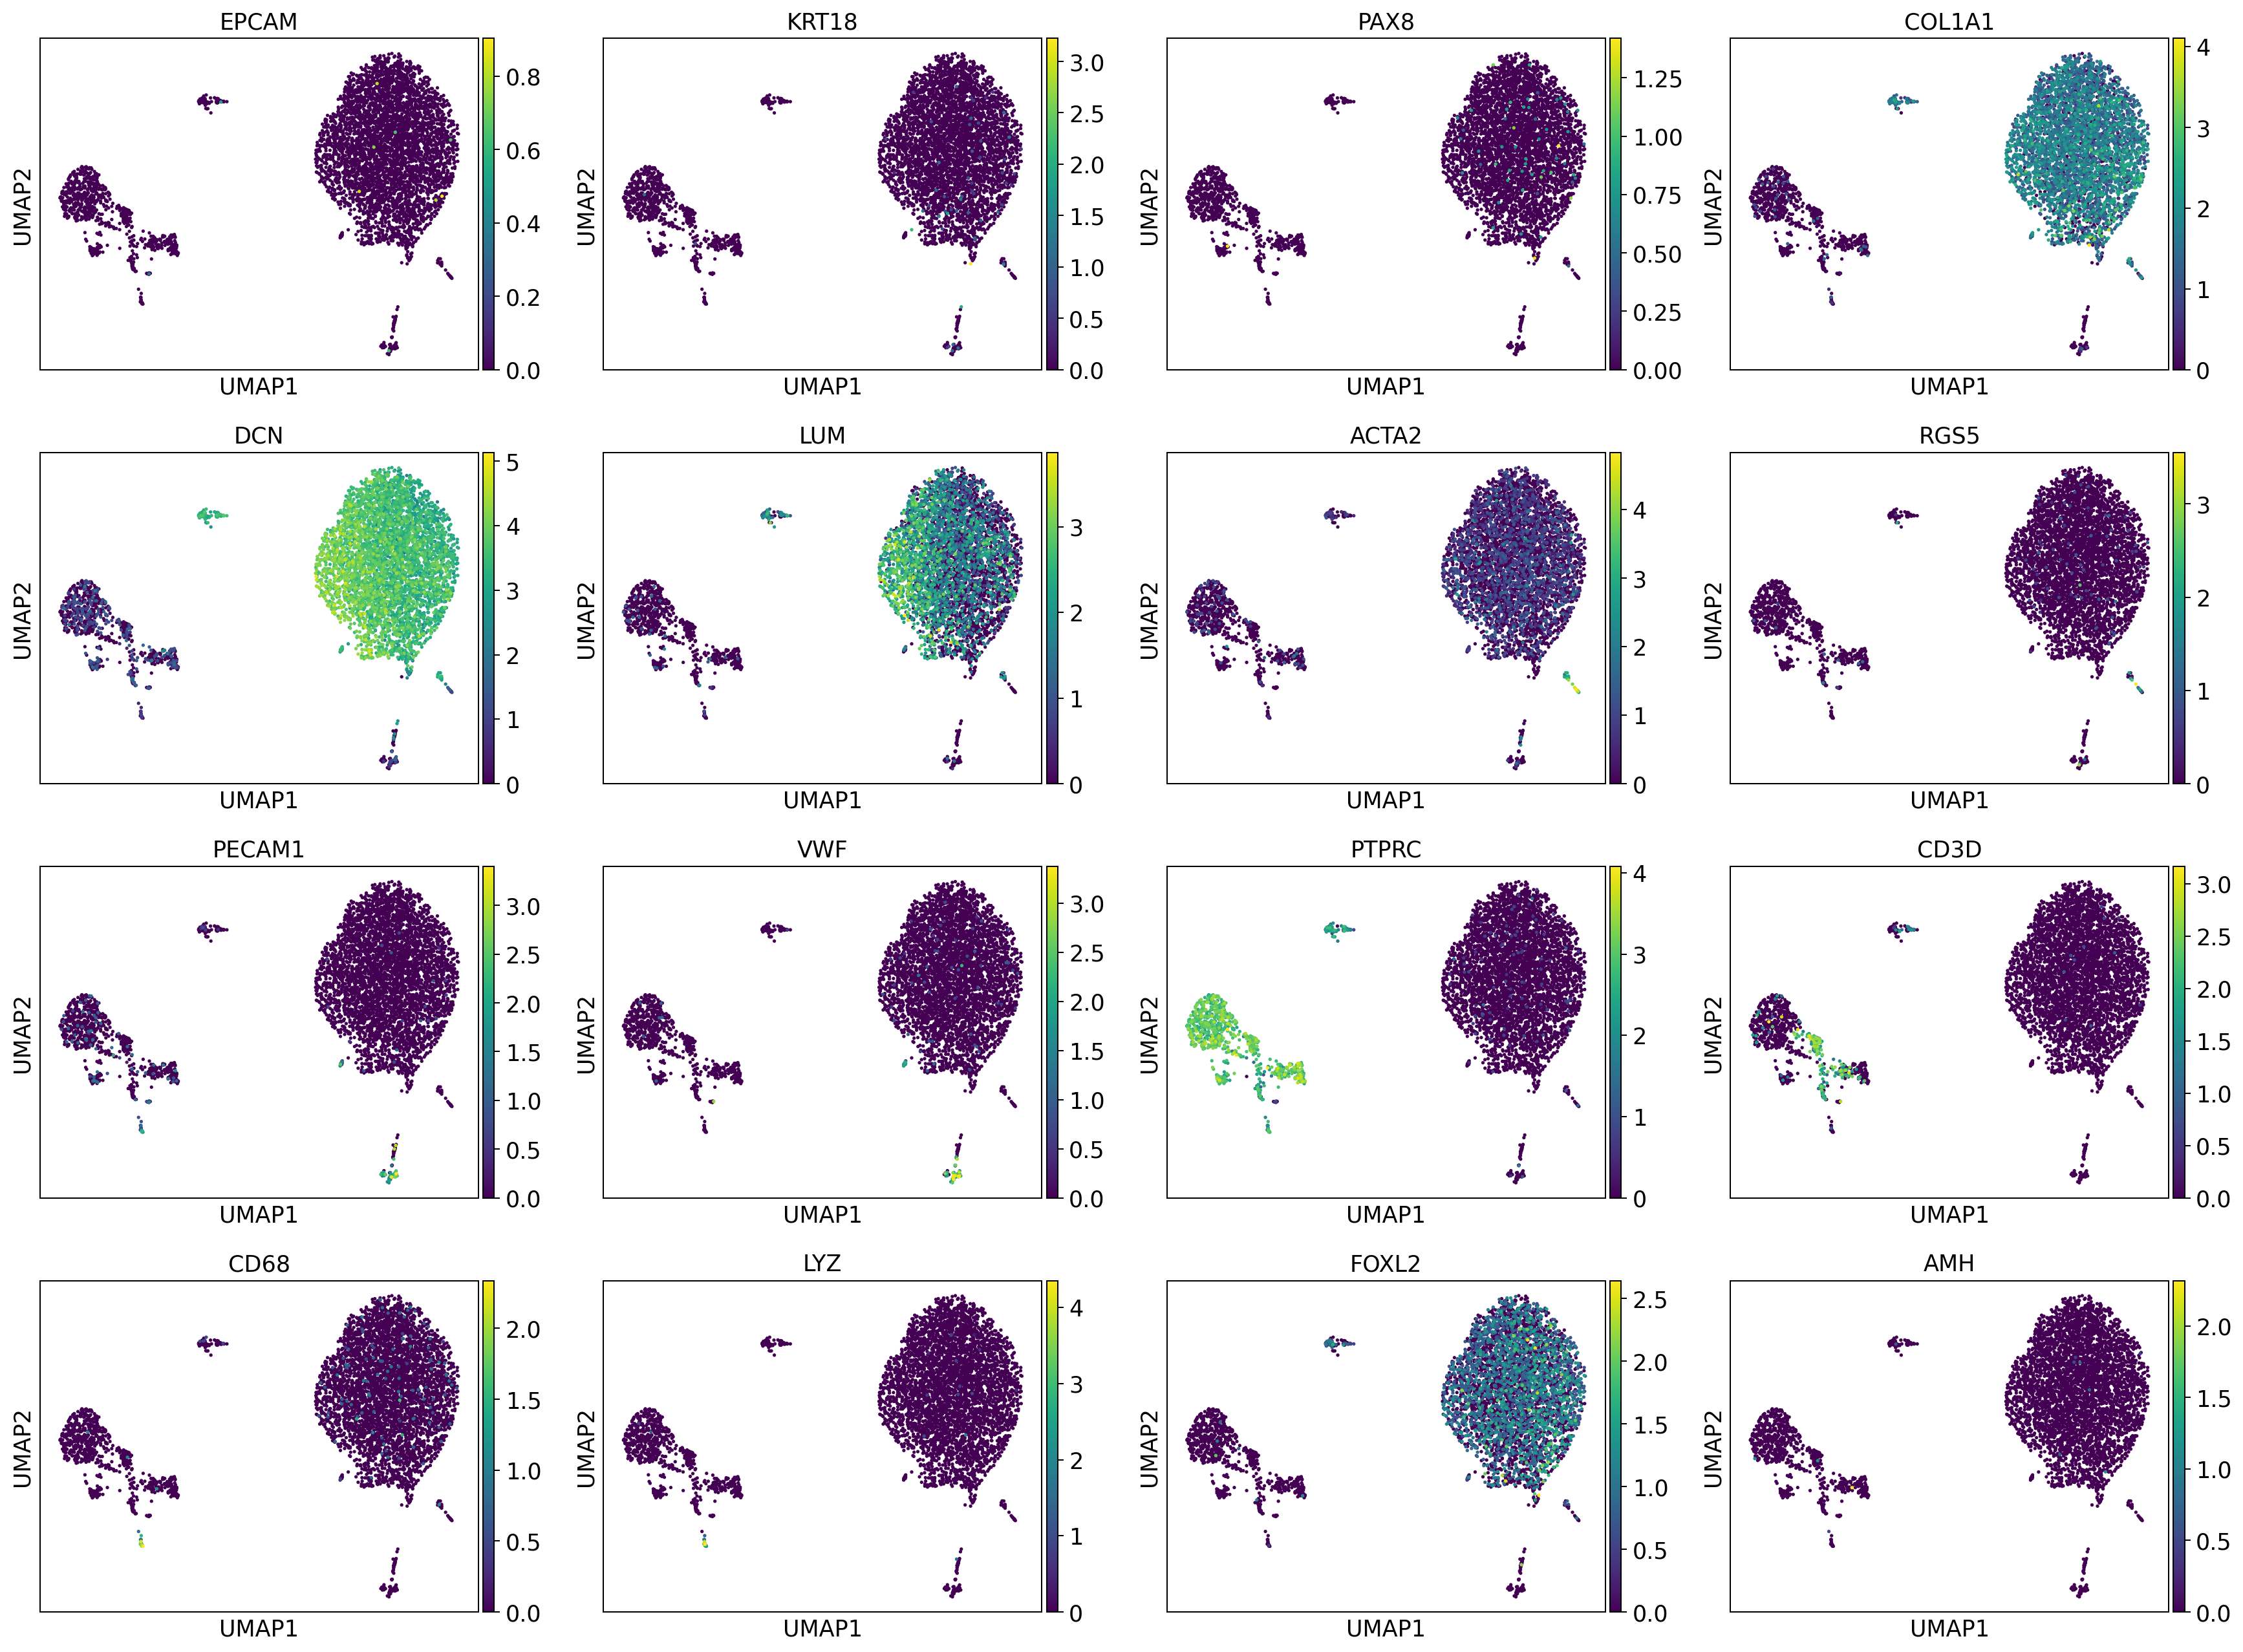

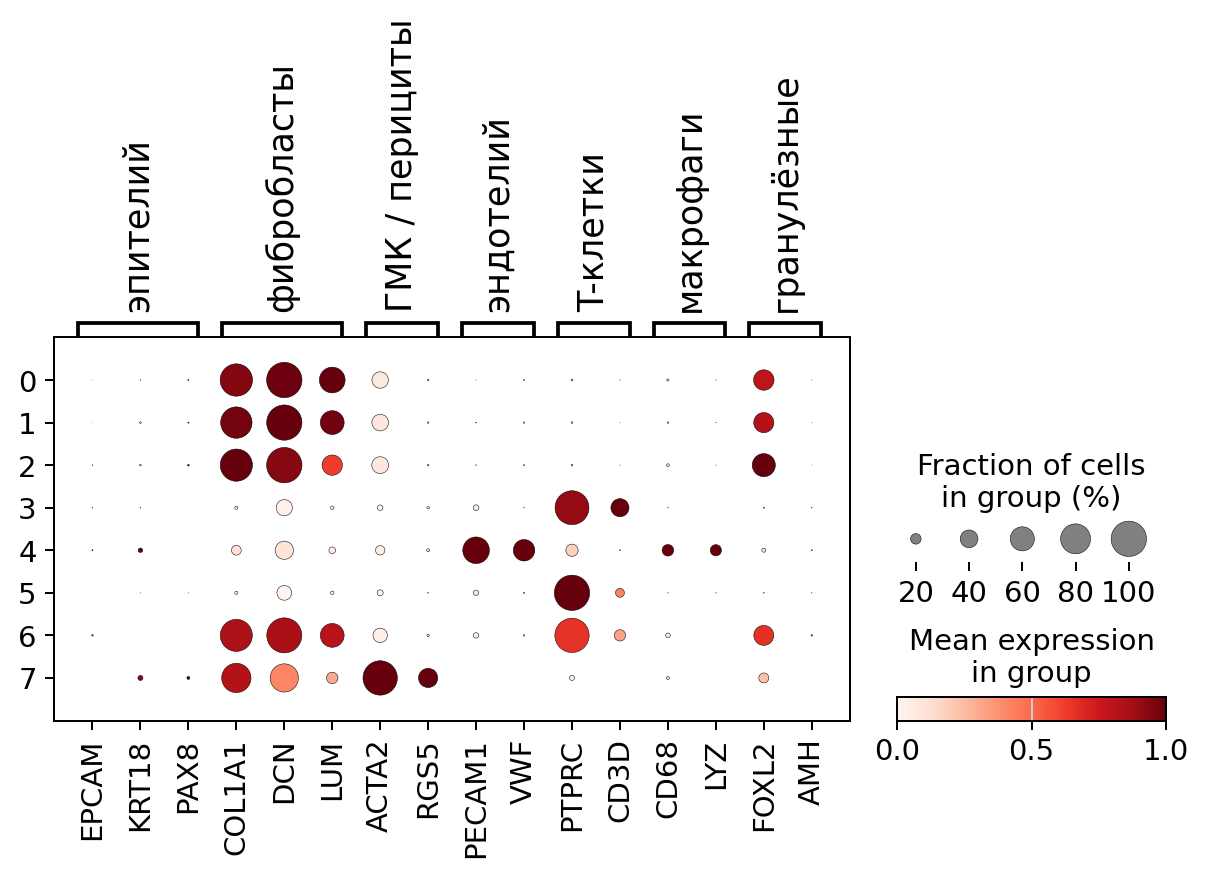

In [42]:
marker_groups = {
    "эпителий": ["EPCAM", "KRT18", "PAX8"],
    "фибробласты": ["COL1A1", "DCN", "LUM"],
    "ГМК / перициты": ["ACTA2", "RGS5"],
    "эндотелий": ["PECAM1", "VWF"],
    "T-клетки": ["PTPRC", "CD3D"],
    "макрофаги": ["CD68", "LYZ"],
    "гранулёзные": ["FOXL2", "AMH"],
}

found = {group: [g for g in genes if g in adata.var_names] for group, genes in marker_groups.items()}
absent = [g for genes in marker_groups.values() for g in genes if g not in adata.var_names]
found = {group: genes for group, genes in found.items() if genes}
print("нет в данных:", absent)

sc.pl.umap(adata, color=[g for genes in found.values() for g in genes], ncols=4, size=18)
sc.pl.dotplot(adata, found, groupby=main_key, standard_scale="var")

Основная масса пробы - стромальные фибробласты: кластеры 0, 1 и 2 (4482 клетки из 5479) - высокий `COL1A1`, `DCN` и `LUM` и не экспрессируют `PTPRC`. Кластер 7 отличается от них `ACTA2` и `RGS5` - похоже на гладкомышечные клетки или перициты, кластер 4 `PECAM1` и `VWF`, то есть эндотелий. Иммунная часть - кластеры 3 и 5 с `PTPRC`, причём `CD3D` виден только в 3, так что T-клетки это скорее он.

Эпителия в пробе практически нет: `EPCAM`, `KRT18` и `PAX8` пустые во всех кластерах - ожидаемо, поверхностный эпителий яичника это один слой клеток и при дезагрегации он почти не попадает в суспензию. `FOXL2` размазан по всем стромальным кластерам и потому неинформативен: вне фолликула его экспрессирует и строма. `AMH` не детектируется совсем, значит гранулёзных клеток в пробе нет. Кластер 6 одновременно даёт стромальные маркеры и `PTPRC` - это может быть переходное состояние, а может быть дублеты; по двум-трём генам отличить сложно.


## 8. Бонус

In [43]:
from sklearn.metrics import adjusted_rand_score

for first, second in [("leiden_0.2", "leiden_0.5"), ("leiden_0.5", "leiden_1.0")]:
    ari = adjusted_rand_score(adata.obs[first], adata.obs[second])
    print(f"ARI({first}, {second}) = {ari:.3f}")

ARI(leiden_0.2, leiden_0.5) = 0.291
ARI(leiden_0.5, leiden_1.0) = 0.258


ARI между соседними разрешениями низкий (0,29 и 0,26) - разбиения расходятся сильно. При 0.2 один кластер держит 4482 клетки из 5479, и при переходе к 0.5 и 1.0 он дробится, а дробление крупного кластера ARI штрафует максимально. Устойчивая часть — мелкие обособленные группы (эндотелий, ГМК, T-клетки): они переживают все три разрешения почти без изменений. Значит, граница внутри стромального массива зависит от выбранного resolution, а деление на строму / иммунные / сосудистые клетки — нет.

## 9. Сохраняем результат


In [44]:
result_path = DATA / f"{SAMPLE}_after_clustering.h5ad"
adata.write_h5ad(result_path, compression="gzip")
print(result_path, f"{result_path.stat().st_size / 1e6:.1f} МБ")

data/ovary/GSM5599220_after_clustering.h5ad 65.9 МБ
